# RQ2: Can the original source of a text still be identified after paraphrasing, and how does that compare with round-trip translation?

**Question.** Each original T0 text was written by a human (XSum) or by one of six LLM generators. A classifier trained on original texts learns to recognise this **source label**. How well does it still recognise the source after one, two or three rewrites by an English paraphraser (ChatGPT, PaLM, Dipper, Pegasus), compared with English → Spanish → English round-trip translation (MADLAD-400-3B, NLLB-200-1.3B, Qwen3-4B, from Samer's RQ2)?

**Protocol: Samer's, reproduced exactly** (`pilot.attribution`, ported from his `sot_research.classify` / `features`):
- **Classes:** the 7 source labels. Chance is 1/7.
- **Documents:** his 200 XSum T0 documents (31 articles). The texts are byte-identical to ours.
- **Folds:** 5 folds over original article IDs × 5 shufflings (seed 6120). An article's texts (every source, rewriter and round) are always on one side.
- **Training:** T0 texts of the training articles only. The models never see a rewrite.
- **Models:** fixed hyperparameters.
  - TF-IDF word 1-2-grams + logistic regression
  - TF-IDF character 2-5-grams + logistic regression
  - his 187 stylometric features + logistic regression
  - a length-only control
- **Uncertainty:** SD over the 5 shufflings, and a 95% article-cluster bootstrap CI (1,000 resamples).

**Additions to his protocol**
1. Our T0 predictions are checked against his, so his translation predictions and our paraphrase predictions come from identically trained classifiers.
2. **Retained attribution** = (macro-F1 at Tk − chance) / (macro-F1 at T0 − chance). This is RQ1's 1 → 0 scale: 1 means as identifiable as the original, 0 means chance.
3. **Length control:** each model's gain over the length-only model, plus a run with every text cut to its first 50 words.
4. **The shared-opening removal is the primary analysis.** The six LLM texts start with the first ~30 words of the human article; paraphrasers, like Qwen, rewrite that opening differently in each text.
5. **Takeover by the rewriter's own style:** are ChatGPT paraphrases increasingly attributed to OpenAI, and PaLM paraphrases to PaLM?

Inputs come from `scripts/import_samer_rq1.py --files-only` (Samer's files) and `scripts/rq2_attribution.py` (our paraphrase predictions, ~3 min).

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from pilot.attribution import LENGTH_COLS, MODELS, article_folds, confusion, per_class, scores, style_columns
from pilot.config import ROOT, load_config

warnings.filterwarnings("ignore", category=FutureWarning)
cfg = load_config()
DERIVED = cfg["paths"]["derived"]
OUT = cfg["paths"]["results"] / "rq2_attribution"
OUT.mkdir(parents=True, exist_ok=True)
SEED, N_BOOT = cfg["seed"], 1000

LABELS = ["Human", "BigScience", "Eleuther-AI", "LLAMA", "OpenAI", "PaLM", "Tsinghua"]
CHANCE = 1 / len(LABELS)
PARAPHRASERS = ["chatgpt", "palm", "dipper", "pegasus(full)"]
TRANSLATORS = ["madlad-3b", "nllb", "qwen3-4b"]
REWRITERS = PARAPHRASERS + TRANSLATORS
LABEL = {"original": "Original", "chatgpt": "ChatGPT", "palm": "PaLM", "dipper": "Dipper", "pegasus(full)": "Pegasus",
         "madlad-3b": "MADLAD-400-3B", "nllb": "NLLB-200-1.3B", "qwen3-4b": "Qwen3-4B"}
MODEL_NAME = {"tfidf_word": "Word n-grams", "tfidf_char": "Char n-grams", "stylometric": "Stylometric",
              "length_only": "Length only"}
ABL_NAME = {"full_text": "Full text", "opening_removed": "Opening removed", "truncated_50": "Opening removed, first 50 words"}

# Same palette and order as RQ1 (validated: CVD ΔE ≥ 9.1; aqua / yellow / magenta < 3:1 contrast, so every chart
# also has a legend, dashed translators and a CSV table)
COLOR = {"chatgpt": "#2a78d6", "palm": "#eb6834", "dipper": "#1baf7a", "pegasus(full)": "#eda100",
         "madlad-3b": "#e87ba4", "nllb": "#008300", "qwen3-4b": "#6250d6"}
MARKER = {"chatgpt": "o", "palm": "s", "dipper": "^", "pegasus(full)": "D", "madlad-3b": "v", "nllb": "P", "qwen3-4b": "X"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.labelsize": 9, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "lines.linewidth": 2, "lines.markersize": 6,
    "legend.frameon": False, "legend.fontsize": 8, "font.size": 9,
})

def save(fig, name, table=None):
    fig.savefig(OUT / f"{name}.png")
    if table is not None:
        table.to_csv(OUT / f"{name}.csv", index=False)

need = ["samer_rq2_predictions.parquet", "samer_rq2_splits.csv", "samer_text_features.parquet", "samer_pair_metrics.parquet",
        "rq2_paraphrase_predictions.parquet", "rq2_features.parquet", "rq2_texts.parquet"]
missing = [f for f in need if not (DERIVED / f).exists()]
assert not missing, f"missing {missing}: run scripts/import_samer_rq1.py --files-only, then scripts/rq2_attribution.py"
ours = pd.read_parquet(DERIVED / "rq2_paraphrase_predictions.parquet")
his = pd.read_parquet(DERIVED / "samer_rq2_predictions.parquet").rename(columns={"translator": "rewriter"})
texts = pd.read_parquet(DERIVED / "rq2_texts.parquet")
print("results ->", OUT.relative_to(ROOT), "| our predictions:", f"{len(ours):,}", "| Samer's:", f"{len(his):,}")

results -> results/rq2_attribution | our predictions: 153,780 | Samer's: 79,320


## 1. Is the port identical to Samer's?

Three checks on texts both pipelines share (the 200 T0 originals):
1. **Features:** our stylometric and length features vs his published per-text features.
2. **Folds:** our article-to-fold assignment vs his `splits.csv`.
3. **Predictions:** our out-of-fold T0 predictions vs his, model by model, for the full and opening-removed texts.

If the T0 predictions agree, the classifiers are the same, so his predictions on translations and ours on paraphrases can be compared directly.

In [7]:
# 1.1 Features, folds and T0 predictions vs Samer's
feats = pd.read_parquet(DERIVED / "rq2_features.parquet")
STYLE = style_columns(feats)
hf = pd.read_parquet(DERIVED / "samer_text_features.parquet")
hf = hf[hf.stage == "T0"].drop_duplicates("text_id")
mine = feats[(feats.variant == "full_text") & feats.text_id.str.endswith("|original|T0")]
fj = mine.merge(hf[["text_id"] + STYLE + ["n_words", "n_sentences"]], on="text_id", suffixes=("", "_samer"))
fdiff = pd.Series({c: (fj[c] - fj[f"{c}_samer"]).abs().max() for c in STYLE + ["n_words", "n_sentences"]})
print(f"1. features: {len(fj)} T0 texts matched | {len(STYLE)} stylometric columns (Samer: {len(style_columns(hf))}) | "
      f"max |diff| over all columns: {fdiff.max():.2e} | columns differing > 1e-9: {(fdiff > 1e-9).sum()}")

splits = pd.read_csv(DERIVED / "samer_rq2_splits.csv")
same = all(article_folds(splits.article_id, 5, SEED + r) == dict(zip(g.article_id, g.fold))
           for r, g in splits.groupby("repeat"))
print(f"2. folds: {splits.article_id.nunique()} articles x {splits.repeat.nunique()} repeats | identical to Samer's: {same}")

K = ["text_id", "repeat", "model", "ablation"]
t0_ours = ours[(ours.eval_set == "original|T0") & ours.ablation.isin(["full_text", "opening_removed"])]
t0_his = his[his.eval_set == "original|T0"]
pj = t0_ours.merge(t0_his[K + ["y_pred", "fold"]], on=K, suffixes=("", "_samer"), validate="1:1")
assert len(pj) == len(t0_his), "T0 predictions don't line up"
assert (pj.fold == pj.fold_samer).all()
agree = (pj.assign(same=pj.y_pred == pj.y_pred_samer).groupby(["ablation", "model"]).same.mean()
         .unstack().reindex(columns=MODELS).rename(columns=MODEL_NAME))
agree.round(4).reset_index().to_csv(OUT / "port_agreement_T0.csv", index=False)
print(f"3. T0 predictions: {len(pj):,} matched; share identical to Samer's:")
agree.round(4)

1. features: 200 T0 texts matched | 187 stylometric columns (Samer: 187) | max |diff| over all columns: 0.00e+00 | columns differing > 1e-9: 0
2. folds: 31 articles x 5 repeats | identical to Samer's: True
3. T0 predictions: 8,000 matched; share identical to Samer's:


model,Word n-grams,Char n-grams,Stylometric,Length only
ablation,,,,
full_text,1.0,1.0,1.0,1.0
opening_removed,1.0,1.0,1.0,1.0


## 2. Paraphrase vs translation: how much source signal survives?

- **Cohort:** documents complete to T3 for all three translators *and* all four paraphrasers, so every rewriter is scored on the same documents.
- **T0 baseline:** identical for both families, since it is the same classifier on the same originals.
- **Primary analysis:** the opening-removed texts. The full-text results are kept as a supplement.

In [3]:
# 2.1 Pool our paraphrase predictions with Samer's translation predictions on the common cohort, and score them
pm = pd.read_parquet(DERIVED / "samer_pair_metrics.parquet")
t3 = pm[(pm.kind == "cumulative") & (pm.hyp_stage == "T3") & pm.translator.isin(TRANSLATORS)]
complete_tr = set.intersection(*(set(t3[t3.translator == t].item_id) for t in TRANSLATORS))
complete_pa = set.intersection(*(set(texts[(texts.rewriter == p) & (texts.stage == "T3")].item_id) for p in PARAPHRASERS))
COHORT = complete_tr & complete_pa

par = ours[ours.eval_set != "original|T0"]
t0 = ours[ours.eval_set == "original|T0"].assign(rewriter="original")
tra = his[his.eval_set != "original|T0"]
allp = pd.concat([t0, par, tra], ignore_index=True)
allp = allp[allp.item_id.isin(COHORT)]
BY = ["model", "ablation", "rewriter", "stage"]
sc = scores(allp, BY, LABELS, n_boot=N_BOOT, seed=SEED)

# Retained attribution: 1 = as identifiable as the original, 0 = chance
base = sc[sc.rewriter == "original"].set_index(["model", "ablation"]).macro_f1
sc["retained"] = [(f - CHANCE) / (base[(m, a)] - CHANCE) for f, m, a in zip(sc.macro_f1, sc.model, sc.ablation)]
sc.to_csv(OUT / "scores.csv", index=False)
print(f"cohort: {len(COHORT)} documents on {allp.article_id.nunique()} articles "
      f"(complete for all translators: {len(complete_tr)}, for all paraphrasers: {len(complete_pa)})")

def cell(r):
    return f"{r.macro_f1:.3f} [{r.macro_f1_ci_low:.3f}, {r.macro_f1_ci_high:.3f}]"

PRIMARY = "opening_removed"
p = sc[sc.ablation == PRIMARY].copy()
p["cell"] = p.apply(cell, axis=1)
p["rw"] = p.rewriter.map(LABEL) + " " + p.stage
order = ["Original T0"] + [f"{LABEL[r]} T{k}" for r in REWRITERS for k in (1, 2, 3)]
print("Macro-F1 [95% CI], opening removed (chance 0.143):")
p.pivot(index="rw", columns="model", values="cell").reindex(order)[MODELS].rename(columns=MODEL_NAME)

cohort: 178 documents on 31 articles (complete for all translators: 193, for all paraphrasers: 184)
Macro-F1 [95% CI], opening removed (chance 0.143):


model,Word n-grams,Char n-grams,Stylometric,Length only
rw,,,,
Original T0,"0.428 [0.366, 0.486]","0.465 [0.409, 0.513]","0.422 [0.376, 0.463]","0.323 [0.278, 0.365]"
ChatGPT T1,"0.298 [0.248, 0.348]","0.268 [0.214, 0.323]","0.228 [0.184, 0.267]","0.208 [0.165, 0.255]"
ChatGPT T2,"0.275 [0.229, 0.323]","0.244 [0.201, 0.289]","0.200 [0.157, 0.241]","0.194 [0.162, 0.225]"
ChatGPT T3,"0.267 [0.218, 0.316]","0.236 [0.189, 0.278]","0.221 [0.178, 0.259]","0.194 [0.159, 0.230]"
PaLM T1,"0.345 [0.280, 0.402]","0.355 [0.305, 0.402]","0.273 [0.219, 0.326]","0.273 [0.226, 0.324]"
PaLM T2,"0.321 [0.269, 0.368]","0.326 [0.275, 0.376]","0.249 [0.197, 0.302]","0.282 [0.228, 0.331]"
PaLM T3,"0.310 [0.253, 0.361]","0.319 [0.273, 0.366]","0.253 [0.207, 0.300]","0.267 [0.216, 0.316]"
Dipper T1,"0.235 [0.181, 0.285]","0.339 [0.285, 0.389]","0.179 [0.131, 0.226]","0.229 [0.174, 0.281]"
Dipper T2,"0.260 [0.209, 0.301]","0.312 [0.253, 0.370]","0.160 [0.121, 0.198]","0.286 [0.229, 0.349]"


Translation - paraphrase, macro-F1 at T3 (pooled per family; 95% article-cluster CI):
Retained attribution at T3, opening removed (1 = as identifiable as the original, 0 = chance):
Gain over the length-only control (macro-F1), opening removed: Original = T0, rewriters = T3


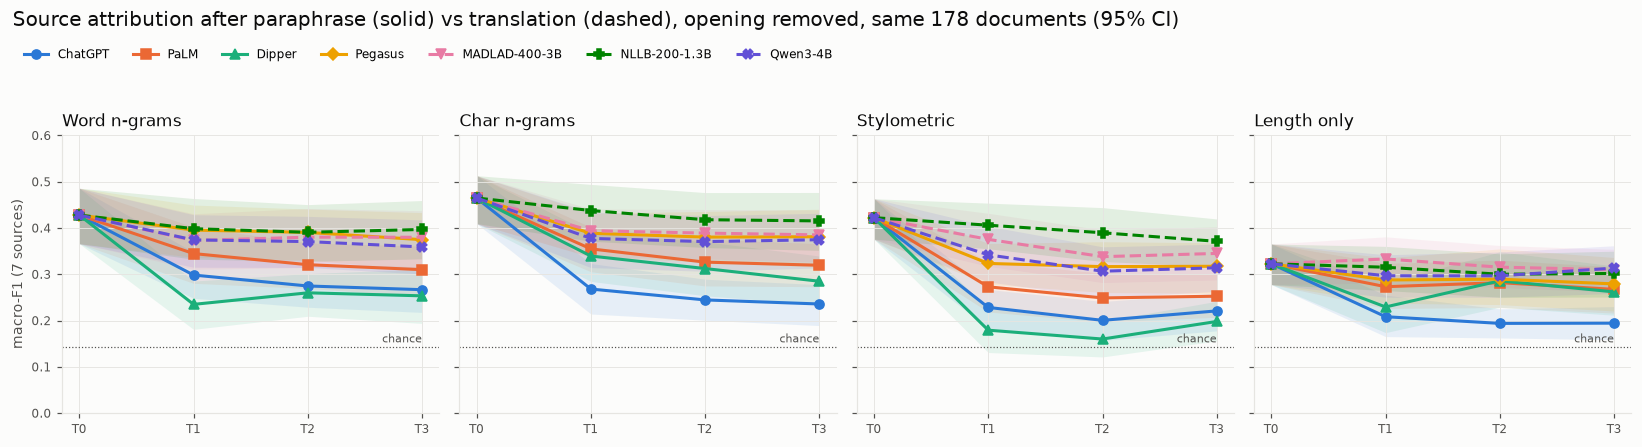

,ablation,model,translation,paraphrase,gap,ci_low,ci_high
0,Full text,Length only,0.295,0.255,0.040,0.009,0.073
1,Opening removed,Length only,0.311,0.265,0.046,0.012,0.083
2,Full text,Stylometric,0.346,0.245,0.101,0.065,0.136
3,Opening removed,Stylometric,0.346,0.253,0.093,0.062,0.125
4,Full text,Char n-grams,0.392,0.309,0.083,0.043,0.121
5,Opening removed,Char n-grams,0.392,0.310,0.083,0.044,0.123
6,Full text,Word n-grams,0.328,0.303,0.026,-0.010,0.062
7,Opening removed,Word n-grams,0.380,0.305,0.075,0.034,0.117


model,Word n-grams,Char n-grams,Stylometric,Length only
who,,,,
ChatGPT,0.43,0.29,0.28,0.29
PaLM,0.59,0.55,0.39,0.69
Dipper,0.39,0.44,0.20,0.66
Pegasus,0.81,0.74,0.62,0.76
MADLAD-400-3B,0.83,0.75,0.72,0.93
NLLB-200-1.3B,0.89,0.85,0.82,0.88
Qwen3-4B,0.76,0.72,0.61,0.95


model,Word n-grams,Char n-grams,Stylometric
who,,,
Original,0.105,0.142,0.100
ChatGPT,0.072,0.041,0.026
PaLM,0.043,0.052,-0.015
Dipper,-0.009,0.023,-0.064
Pegasus,0.095,0.102,0.038
MADLAD-400-3B,0.070,0.075,0.035
NLLB-200-1.3B,0.095,0.113,0.069
Qwen3-4B,0.046,0.061,0.001


In [4]:
# 2.2 Curves, retained attribution at T3, and the translation - paraphrase gap with an article-cluster bootstrap CI
from pilot.attribution import macro_f1

def curve_plot(s, ablation, title, fname):
    fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True)
    for ax, m in zip(axes, MODELS):
        g = s[(s.model == m) & (s.ablation == ablation)]
        o = g[g.rewriter == "original"].iloc[0]
        for r in REWRITERS:
            h = g[g.rewriter == r].sort_values("stage")
            x = [0, 1, 2, 3]
            ax.fill_between(x, [o.macro_f1_ci_low, *h.macro_f1_ci_low], [o.macro_f1_ci_high, *h.macro_f1_ci_high],
                            color=COLOR[r], alpha=0.10, linewidth=0)
            ax.plot(x, [o.macro_f1, *h.macro_f1], color=COLOR[r], marker=MARKER[r],
                    linestyle="--" if r in TRANSLATORS else "-", label=LABEL[r])
        ax.axhline(CHANCE, color=MUTED, linewidth=0.8, linestyle=":")
        ax.annotate("chance", (3, CHANCE), xytext=(0, 3), textcoords="offset points", ha="right", fontsize=7, color=MUTED)
        ax.set_xticks([0, 1, 2, 3], ["T0", "T1", "T2", "T3"]); ax.set_title(MODEL_NAME[m], loc="left")
        ax.set_ylim(0, 0.6)
    axes[0].set_ylabel("macro-F1 (7 sources)")
    h_, l_ = axes[0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="upper left", bbox_to_anchor=(0.01, 0.94), ncol=7)
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, color=INK, y=1.0)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    save(fig, fname)
    plt.show()

curve_plot(sc, PRIMARY, f"Source attribution after paraphrase (solid) vs translation (dashed), opening removed, "
           f"same {len(COHORT)} documents (95% CI)", "attribution_curves")

# Family gap at T3: macro-F1 of all translator predictions pooled minus all paraphraser predictions pooled,
# with articles resampled jointly for both families (paired: same documents, same folds)
rng = np.random.default_rng(SEED)
gap_rows = []
for (m, a), g in allp[allp.stage == "T3"].groupby(["model", "ablation"]):
    if a not in ("full_text", "opening_removed"):
        continue
    fam = np.where(g.rewriter.isin(TRANSLATORS), "translation", "paraphrase")
    yt, yp, art = g.y_true.to_numpy(), g.y_pred.to_numpy(), g.article_id.to_numpy()
    idx = {x: np.flatnonzero(art == x) for x in np.unique(art)}
    def fgap(sel):
        tr, pa = sel[fam[sel] == "translation"], sel[fam[sel] == "paraphrase"]
        return macro_f1(yt[tr], yp[tr], LABELS), macro_f1(yt[pa], yp[pa], LABELS)
    ft, fp = fgap(np.arange(len(g)))
    boots = []
    for _ in range(N_BOOT):
        sel = np.concatenate([idx[x] for x in rng.choice(list(idx), len(idx), replace=True)])
        bt, bp = fgap(sel)
        boots.append(bt - bp)
    gap_rows.append({"ablation": a, "model": m, "translation": ft, "paraphrase": fp, "gap": ft - fp,
                     "ci_low": np.percentile(boots, 2.5), "ci_high": np.percentile(boots, 97.5)})
gap = pd.DataFrame(gap_rows)
gap.round(4).to_csv(OUT / "family_gap_T3.csv", index=False)

# Retained attribution and gain over the length-only control, at T3
t3s = sc[(sc.stage == "T3") | (sc.rewriter == "original")].copy()
t3s["who"] = t3s.rewriter.map(LABEL)
ret = (t3s[(t3s.ablation == PRIMARY) & (t3s.rewriter != "original")]
       .pivot(index="who", columns="model", values="retained").reindex([LABEL[r] for r in REWRITERS])[MODELS])
lo = t3s[t3s.model == "length_only"].set_index(["ablation", "rewriter", "stage"]).macro_f1
t3s["gain_over_length"] = [f - lo[(a, r, s)] for f, a, r, s in zip(t3s.macro_f1, t3s.ablation, t3s.rewriter, t3s.stage)]
gain = (t3s[(t3s.ablation == PRIMARY) & (t3s.model != "length_only")]
        .pivot(index="who", columns="model", values="gain_over_length")
        .reindex(["Original"] + [LABEL[r] for r in REWRITERS])[MODELS[:3]])
ret.round(3).reset_index().to_csv(OUT / "retained_T3.csv", index=False)
gain.round(3).reset_index().to_csv(OUT / "gain_over_length_T3.csv", index=False)
print("Translation - paraphrase, macro-F1 at T3 (pooled per family; 95% article-cluster CI):")
display(gap.assign(model=gap.model.map(MODEL_NAME), ablation=gap.ablation.map(ABL_NAME)).round(3))
print("Retained attribution at T3, opening removed (1 = as identifiable as the original, 0 = chance):")
display(ret.rename(columns=MODEL_NAME).round(2))
print("Gain over the length-only control (macro-F1), opening removed: Original = T0, rewriters = T3")
gain.rename(columns=MODEL_NAME).round(3)

## 3. Length control: texts cut to their first 50 words

Sources differ strongly in length, and paraphrasers change length while translators barely do. So a model could "recognise" a source mostly from length, and lose that cue when a paraphraser changes it. Here every text (training and test) has its shared opening removed and is then cut to its first 50 words, which leaves almost no length signal. This run is possible for paraphrases only: it needs the texts, and Samer's translations are not in the repo.

In [5]:
# 3.1 Paraphrase attribution with every text cut to 50 words, vs the same texts at full length
tw = texts.set_index("text_id").n_words
words = (texts[texts.item_id.isin(COHORT)].groupby(["rewriter", "stage"]).n_words.median().unstack()
         .reindex(["original"] + PARAPHRASERS).rename(index=LABEL))
lt = sc[sc.ablation.isin([PRIMARY, "truncated_50"]) & sc.rewriter.isin(["original"] + PARAPHRASERS)].copy()
lt["cell"] = lt.apply(cell, axis=1)
lt["rw"] = lt.rewriter.map(LABEL) + " " + lt.stage
lt_tab = (lt[lt.stage.isin(["T0", "T3"])].pivot_table(index="rw", columns=["ablation", "model"], values="cell", aggfunc="first")
          .reindex(["Original T0"] + [f"{LABEL[p]} T3" for p in PARAPHRASERS]))
lt_tab = lt_tab[[(a, m) for a in (PRIMARY, "truncated_50") for m in MODELS]]
lt_tab.columns = [f"{ABL_NAME[a]}: {MODEL_NAME[m]}" for a, m in lt_tab.columns]
lt[["ablation", "model", "rewriter", "stage", "macro_f1", "macro_f1_ci_low", "macro_f1_ci_high", "retained"]].round(4) \
    .to_csv(OUT / "length_control_truncated.csv", index=False)
print("Median words (opening included):")
display(words)
print("Macro-F1 [95% CI] at T0 and T3, opening removed vs also cut to 50 words:")
lt_tab.T

Median words (opening included):
Macro-F1 [95% CI] at T0 and T3, opening removed vs also cut to 50 words:


stage,T0,T1,T2,T3
rewriter,,,,
Original,171.5,NaN,NaN,NaN
ChatGPT,NaN,144.0,144.5,146.5
PaLM,NaN,150.5,149.5,145.0
Dipper,NaN,153.0,136.0,126.5
Pegasus,NaN,125.5,114.0,102.5


rw,Original T0,ChatGPT T3,PaLM T3,Dipper T3,Pegasus T3
Opening removed: Word n-grams,"0.428 [0.366, 0.486]","0.267 [0.218, 0.316]","0.310 [0.253, 0.361]","0.253 [0.194, 0.311]","0.375 [0.310, 0.433]"
Opening removed: Char n-grams,"0.465 [0.409, 0.513]","0.236 [0.189, 0.278]","0.319 [0.273, 0.366]","0.285 [0.234, 0.339]","0.381 [0.315, 0.440]"
Opening removed: Stylometric,"0.422 [0.376, 0.463]","0.221 [0.178, 0.259]","0.253 [0.207, 0.300]","0.198 [0.156, 0.242]","0.317 [0.258, 0.368]"
Opening removed: Length only,"0.323 [0.278, 0.365]","0.194 [0.159, 0.230]","0.267 [0.216, 0.316]","0.262 [0.211, 0.318]","0.279 [0.221, 0.336]"
"Opening removed, first 50 words: Word n-grams","0.359 [0.301, 0.418]","0.162 [0.125, 0.199]","0.181 [0.146, 0.215]","0.159 [0.116, 0.201]","0.300 [0.253, 0.351]"
"Opening removed, first 50 words: Char n-grams","0.352 [0.298, 0.408]","0.150 [0.117, 0.185]","0.176 [0.142, 0.209]","0.186 [0.137, 0.226]","0.265 [0.225, 0.310]"
"Opening removed, first 50 words: Stylometric","0.383 [0.334, 0.435]","0.161 [0.113, 0.203]","0.204 [0.164, 0.247]","0.149 [0.106, 0.196]","0.306 [0.238, 0.369]"
"Opening removed, first 50 words: Length only","0.322 [0.282, 0.362]","0.150 [0.112, 0.185]","0.195 [0.151, 0.240]","0.154 [0.120, 0.190]","0.250 [0.206, 0.292]"


## 4. Does the rewriter's own style take over?

Two paraphrasers have a matching source class: ChatGPT (an OpenAI model) and PaLM. If a paraphraser imposes its own style, its rewrites should be **increasingly attributed to its own family**, whatever their true source. The table shows the share of predictions for each class, pooled over sources, repeats and models trained on originals (char n-grams, opening removed). Only texts whose true source is a *different* class are counted, so an honest classifier stays near its T0 rate.

Share of texts attributed to OpenAI / PaLM among texts from other sources (char n-grams, opening removed):


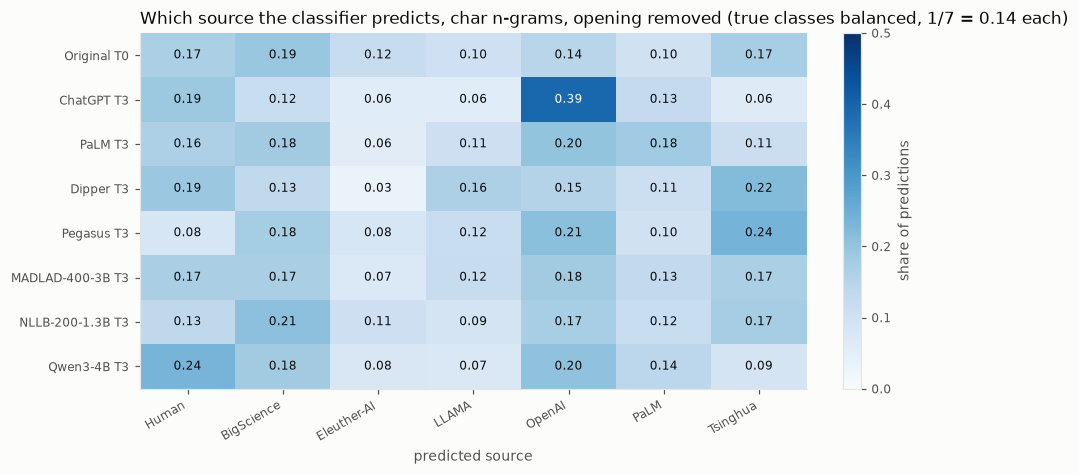

class         OpenAI                       PaLM                     
stage             T0     T1     T2     T3    T0     T1     T2     T3
rw                                                                  
Original       0.034    NaN    NaN    NaN  0.07    NaN    NaN    NaN
ChatGPT          NaN  0.302  0.338  0.338   NaN  0.109  0.110  0.111
PaLM             NaN  0.099  0.107  0.127   NaN  0.139  0.139  0.171
Dipper           NaN  0.069  0.090  0.089   NaN  0.086  0.105  0.099
Pegasus          NaN  0.103  0.113  0.114   NaN  0.078  0.066  0.081
MADLAD-400-3B    NaN  0.089  0.085  0.081   NaN  0.090  0.091  0.094
NLLB-200-1.3B    NaN  0.065  0.074  0.073   NaN  0.085  0.082  0.081
Qwen3-4B         NaN  0.093  0.111  0.113   NaN  0.127  0.117  0.123

In [6]:
# 4.1 Share of rewrites attributed to OpenAI / PaLM (true source excluded), and the full prediction distribution at T3
TAKE_MODEL = "tfidf_char"
pc = allp[(allp.model == TAKE_MODEL) & (allp.ablation == PRIMARY)]
rows = []
for cls in ("OpenAI", "PaLM"):
    d = pc[pc.y_true != cls]
    share = d.assign(hit=d.y_pred == cls).groupby(["rewriter", "stage"]).hit.mean()
    for (r, s), v in share.items():
        rows.append({"class": cls, "rewriter": r, "stage": s, "share": v})
take = pd.DataFrame(rows)
take_tab = (take.assign(rw=take.rewriter.map(LABEL), cs=take["class"] + " " + take.stage)
            .pivot_table(index="rw", columns=["class", "stage"], values="share")
            .reindex(["Original"] + [LABEL[r] for r in REWRITERS]))
take.round(4).to_csv(OUT / "rewriter_takeover.csv", index=False)

dist = (pc[(pc.stage == "T3") | (pc.rewriter == "original")].groupby("rewriter").y_pred.value_counts(normalize=True)
        .unstack().reindex(index=["original"] + REWRITERS, columns=LABELS).fillna(0))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
im = ax.imshow(dist.to_numpy(), cmap="Blues", vmin=0, vmax=0.5, aspect="auto")
ax.set_xticks(range(len(LABELS)), LABELS, rotation=30, ha="right")
ax.set_yticks(range(len(dist)), ["Original T0"] + [f"{LABEL[r]} T3" for r in REWRITERS])
ax.grid(False)
for i in range(dist.shape[0]):
    for j in range(dist.shape[1]):
        v = dist.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.3 else INK)
fig.colorbar(im, ax=ax, fraction=0.03, label="share of predictions")
ax.set_xlabel("predicted source"); ax.set_title("Which source the classifier predicts, char n-grams, opening removed "
                                                "(true classes balanced, 1/7 = 0.14 each)", loc="left")
save(fig, "prediction_distribution_T3", dist.reset_index())
plt.show()
print("Share of texts attributed to OpenAI / PaLM among texts from other sources (char n-grams, opening removed):")
take_tab.round(3)

## 5. Interpretation

Scores are macro-F1 over 7 sources (chance 0.14) on the same 178 documents / 31 articles, opening removed, 5×5 article-grouped CV, trained on originals only.

**1. Paraphrasing erases more of the source signal than round-trip translation.**
- **Family gap at T3:** pooled translation predictions beat pooled paraphrase predictions by +0.08 macro-F1 for char n-grams [0.04, 0.12], +0.09 for stylometric features [0.06, 0.13] and +0.08 for word n-grams [0.03, 0.12]. All three CIs exclude zero.
- **Retained attribution, char n-grams:**
  - translators keep 72-85% of the T0 signal above chance;
  - ChatGPT keeps 29%, Dipper 44%, PaLM 55%;
  - Pegasus keeps 74%, overlapping the translators.
- This mirrors RQ1, where translation preserved wording and style more than paraphrase.

**2. As in RQ1, most of the loss happens in round 1.** Curves are nearly flat after T1 for every rewriter.

**3. Much of what survives paraphrasing is length.**
- **Gain over the length-only control at T3,** char n-grams:
  - translators: +0.06 to +0.11;
  - Pegasus: +0.10;
  - ChatGPT, PaLM and Dipper: only +0.02 to +0.05.
- **Stylometric model:** for PaLM and Dipper it is *no better* than length alone.
- **Cutting every text to 50 words:** ChatGPT, PaLM and Dipper rewrites fall to near chance (0.15-0.20), while Pegasus keeps 0.27-0.31.
- **Caveat on the truncation:** it does not remove length completely. Length-only still scores 0.32 at T0, because some originals are shorter than 50 words after the opening is removed, and sentence- and word-length features remain.

**4. ChatGPT overwrites the source with its own style.**
- Among texts *not* written by OpenAI:
  - originals: 3% are attributed to OpenAI;
  - ChatGPT rewrites: 30% at T1, 34% at T3;
  - other rewriters: 7-13%.
- PaLM shows a weaker version of the same pattern: attributions to PaLM rise from 7% to 17% at T3.
- **What this means:** the classifier is not just losing the source. It is detecting the rewriter. ChatGPT's low attribution score is partly a systematic relabelling, not just noise.

**5. The shared opening is not what the classifiers use** (Samer's finding, reproduced). Removing it leaves T0 scores the same or higher.

## Limitations
- **Small sample:** only 31 articles (about 6 per test fold) and about 25 documents per class. Per-rewriter CIs are ±0.05, so only the family gap and the largest per-rewriter differences are reliable.
- **Narrow setting:** one dataset (XSum), fixed untuned classical models, and greedy decoding for the translators.
- **Length control is paraphrase-only:** the 50-word run needs the texts, which we have for paraphrases but not for Samer's translations.
- **Originals are partly LLM-written:** the six LLM sources are themselves model outputs, so the takeover effect can only be measured for the two rewriters with a matching source class (ChatGPT and PaLM).
- **Next step:** the well-powered version is the full corpus (7 datasets, 2,996 articles). It needs Colab.